# Introduction to Deep Learning Final Project - Breast Cancer Detection
Rachel Bonen, Efi Korenfeld 


In [ ]:
!pip install tabgan

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import collections

import torch
import torch.nn as nn
import torch.optim as optim
import seaborn as sns
import statsmodels.api as sm
import torch.nn.functional as F
from torch.autograd import Variable

from tabgan.sampler import GANGenerator
import sklearn.datasets
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB

from scipy.stats import mannwhitneyu,kstest
from sklearn.metrics import f1_score
from random import randint

from sklearn.preprocessing import StandardScaler  
from sklearn.utils import shuffle 
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

In [ ]:
from google.colab import drive
drive.mount('/content/gdrive')

Mounted at /content/gdrive


Reading the Data:

In [ ]:
data_path = '/content/gdrive/My Drive/Intro_to_Deep_Learning/Project/breast-cancer.csv'
df = pd.read_csv(data_path)

# Introduction

In this project we developed a classifier that classifies breast cancer tumors to their type, Malignant or Benign, based on their characteristics.

The data set can be found in reference [1].

It contains 569 patients classified according to the type of breast tumor they have, and attributes that are characteristics of the tumor.

The following diagram presents the steps we performed in this project:


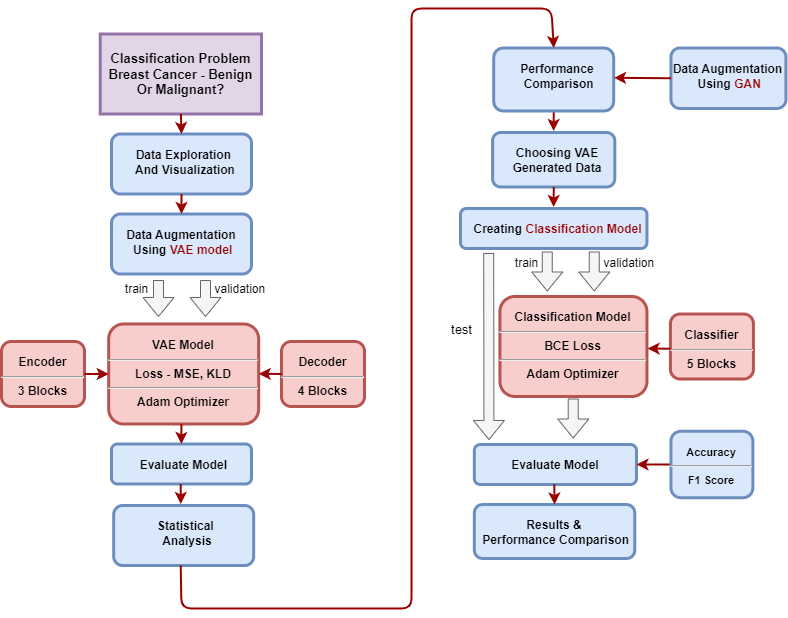

First we performed data exploration and visualization.
The data was unbalanced and since it is not very large, we needed to augment it.


We performed the augmentation using a VAE model we created, and ensured using statistical tests the augmented data is appropriate, we also compared it to a tabular GAN and outperformed it.


Then we created the classification model, we tested different architectures and parameters to obtain the optimal.
Finally, we evaluated our model using multiple benchmarks and compared it to State-Of-The-Art classifiers.


# Data Exploration and Visualization

In [ ]:
df

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,...,25.380,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,...,24.990,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,...,23.570,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,...,14.910,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,...,22.540,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,926424,M,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,...,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115
565,926682,M,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,...,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637
566,926954,M,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,...,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820
567,927241,M,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,...,25.740,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400


"ID" is an irrelevant feature, hence we decided to drop it:

In [ ]:
df=df.drop(columns = ["id"])
df.shape

(569, 31)

In [ ]:
df.describe()

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


Changing the labels of target to numerical values: "M" -> 0, "B" -> 1

In [ ]:
df.loc[df["diagnosis"] == "M", "diagnosis"] = 0
df.loc[df["diagnosis"] == "B", "diagnosis"] = 1
df

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,...,25.380,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890
1,0,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,...,24.990,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902
2,0,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,...,23.570,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758
3,0,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,...,14.910,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300
4,0,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,...,22.540,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,0,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,...,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115
565,0,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,...,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637
566,0,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,...,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820
567,0,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,...,25.740,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400


Seperating the data according to the classification to further analyze the features:

In [ ]:
df_m = df[df['diagnosis']==0]
df_B = df[df['diagnosis']==1]
df_m.describe()


,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
count,212.000000,212.000000,212.000000,212.000000,212.000000,212.000000,212.000000,212.000000,212.000000,212.000000,...,212.000000,212.000000,212.000000,212.000000,212.000000,212.000000,212.000000,212.000000,212.000000,212.000000
mean,17.462830,21.604906,115.365377,978.376415,0.102898,0.145188,0.160775,0.087990,0.192909,0.062680,...,21.134811,29.318208,141.370330,1422.286321,0.144845,0.374824,0.450606,0.182237,0.323468,0.091530
std,3.203971,3.779470,21.854653,367.937978,0.012608,0.053987,0.075019,0.034374,0.027638,0.007573,...,4.283569,5.434804,29.457055,597.967743,0.021870,0.170372,0.181507,0.046308,0.074685,0.021553
min,10.950000,10.380000,71.900000,361.600000,0.073710,0.046050,0.023980,0.020310,0.130800,0.049960,...,12.840000,16.670000,85.100000,508.100000,0.088220,0.051310,0.023980,0.028990,0.156500,0.055040
25%,15.075000,19.327500,98.745000,705.300000,0.094010,0.109600,0.109525,0.064620,0.174050,0.056598,...,17.730000,25.782500,119.325000,970.300000,0.130475,0.244475,0.326425,0.152750,0.276500,0.076302
50%,17.325000,21.460000,114.200000,932.000000,0.102200,0.132350,0.151350,0.086280,0.189900,0.061575,...,20.590000,28.945000,138.000000,1303.000000,0.143450,0.356350,0.404900,0.182000,0.310300,0.087600
75%,19.590000,23.765000,129.925000,1203.750000,0.110925,0.172400,0.203050,0.103175,0.209850,0.067075,...,23.807500,32.690000,159.800000,1712.750000,0.155975,0.447850,0.556175,0.210675,0.359225,0.102625
max,28.110000,39.280000,188.500000,2501.000000,0.144700,0.345400,0.426800,0.201200,0.304000,0.097440,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.170000,0.291000,0.663800,0.207500


In [ ]:
df_B.describe()

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
count,357.000000,357.000000,357.000000,357.000000,357.000000,357.000000,357.000000,357.000000,357.000000,357.000000,...,357.000000,357.000000,357.000000,357.000000,357.000000,357.000000,357.000000,357.000000,357.000000,357.000000
mean,12.146524,17.914762,78.075406,462.790196,0.092478,0.080085,0.046058,0.025717,0.174186,0.062867,...,13.379801,23.515070,87.005938,558.899440,0.124959,0.182673,0.166238,0.074444,0.270246,0.079442
std,1.780512,3.995125,11.807438,134.287118,0.013446,0.033750,0.043442,0.015909,0.024807,0.006747,...,1.981368,5.493955,13.527091,163.601424,0.020013,0.092180,0.140368,0.035797,0.041745,0.013804
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.051850,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156600,0.055210
25%,11.080000,15.150000,70.870000,378.200000,0.083060,0.055620,0.020310,0.015020,0.158000,0.058530,...,12.080000,19.580000,78.270000,447.100000,0.110400,0.112000,0.077080,0.051040,0.240600,0.070090
50%,12.200000,17.390000,78.180000,458.400000,0.090760,0.075290,0.037090,0.023440,0.171400,0.061540,...,13.350000,22.820000,86.920000,547.400000,0.125400,0.169800,0.141200,0.074310,0.268700,0.077120
75%,13.370000,19.760000,86.100000,551.100000,0.100700,0.097550,0.059990,0.032510,0.189000,0.065760,...,14.800000,26.510000,96.590000,670.000000,0.137600,0.230200,0.221600,0.097490,0.298300,0.085410
max,17.850000,33.810000,114.600000,992.100000,0.163400,0.223900,0.410800,0.085340,0.274300,0.095750,...,19.820000,41.780000,127.100000,1210.000000,0.200600,0.584900,1.252000,0.175000,0.422800,0.148600


Observing the values of mean,median and std we see a significant difference between the values of features for the two different classifications.

Also, our data is **not balanced**, there are 212 "M" samples (37%) vs 357 "B" samples (63%). We will perform data augmentation to balance it before the training process.

**Visualizing ditributions of features:**

In [ ]:
def plot_histograms(df):
  plt.figure(figsize=(30,30))
  ind=0
  for i in range(5):
    for j in range(7):
      if ind<len(cols):
        ax_new = plt.subplot(5,7,ind+1)
        sns.histplot(df, x=cols[ind], hue="diagnosis",ax=ax_new)
        ind +=1

cols = list(df.columns)    



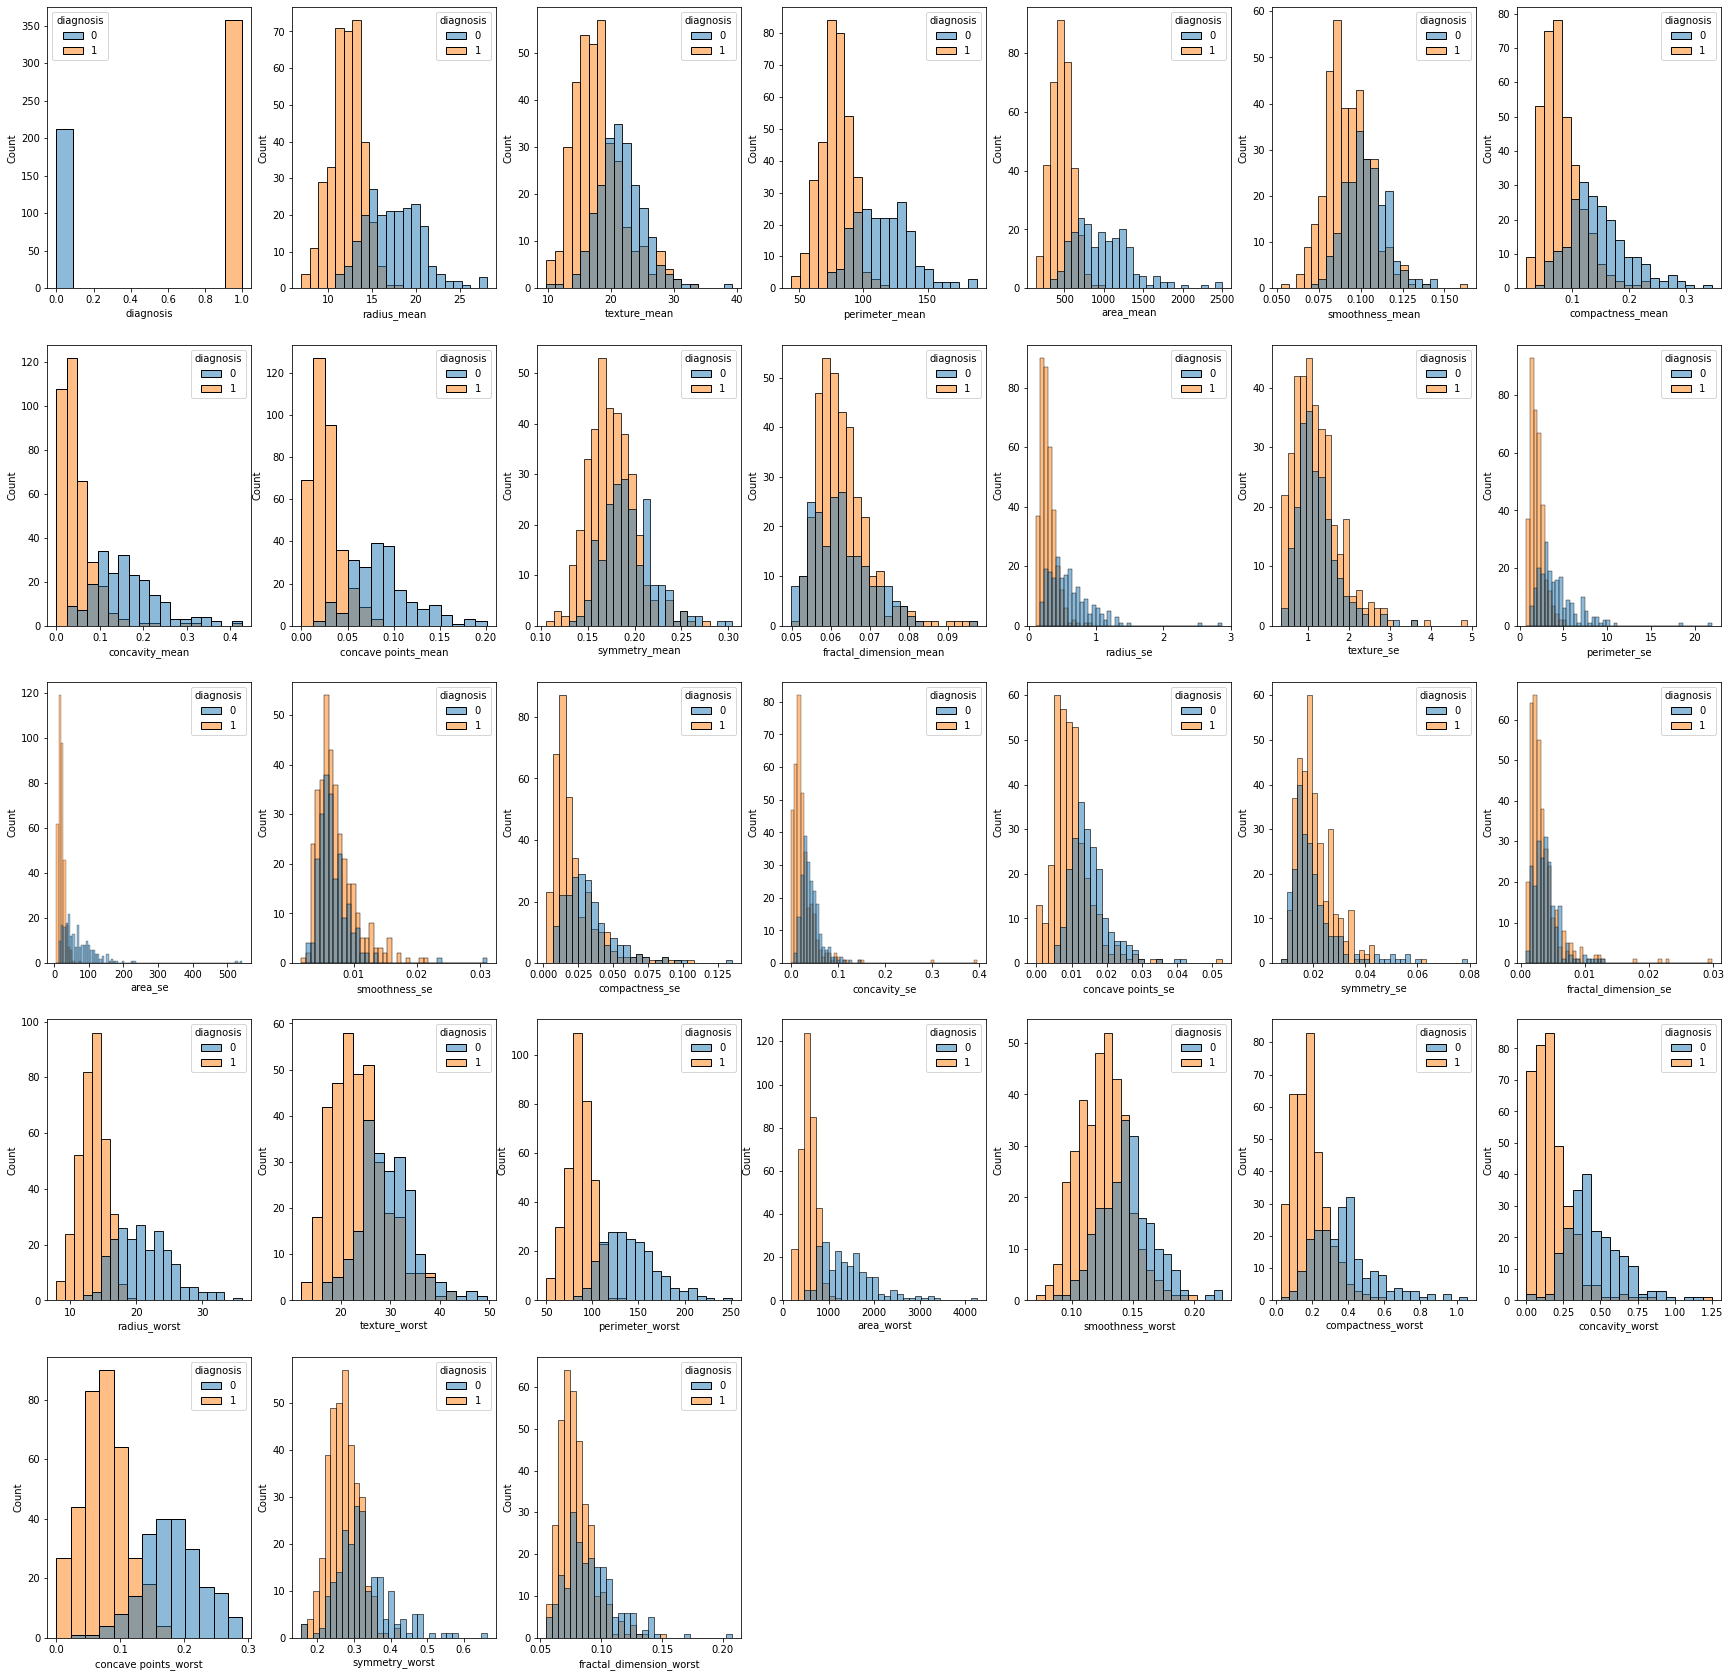

In [ ]:
plot_histograms(df)

Many of the distributions are different, which is good for us and can help us in classifying. Others are more similar but we can still see the difference.

**Visualizing correlations:**

We will viasualize the correlation between each pair of features using the following heatmaps:


In [ ]:
def correlation(df):
  corr=df.corr()
  f, ax = plt.subplots(figsize=(20, 20))
  mask = np.triu(np.ones_like(corr, dtype=bool))
  cmap = sns.diverging_palette(230, 20, as_cmap=True)
  sns.heatmap(corr, annot=True, mask = mask, cmap=cmap)


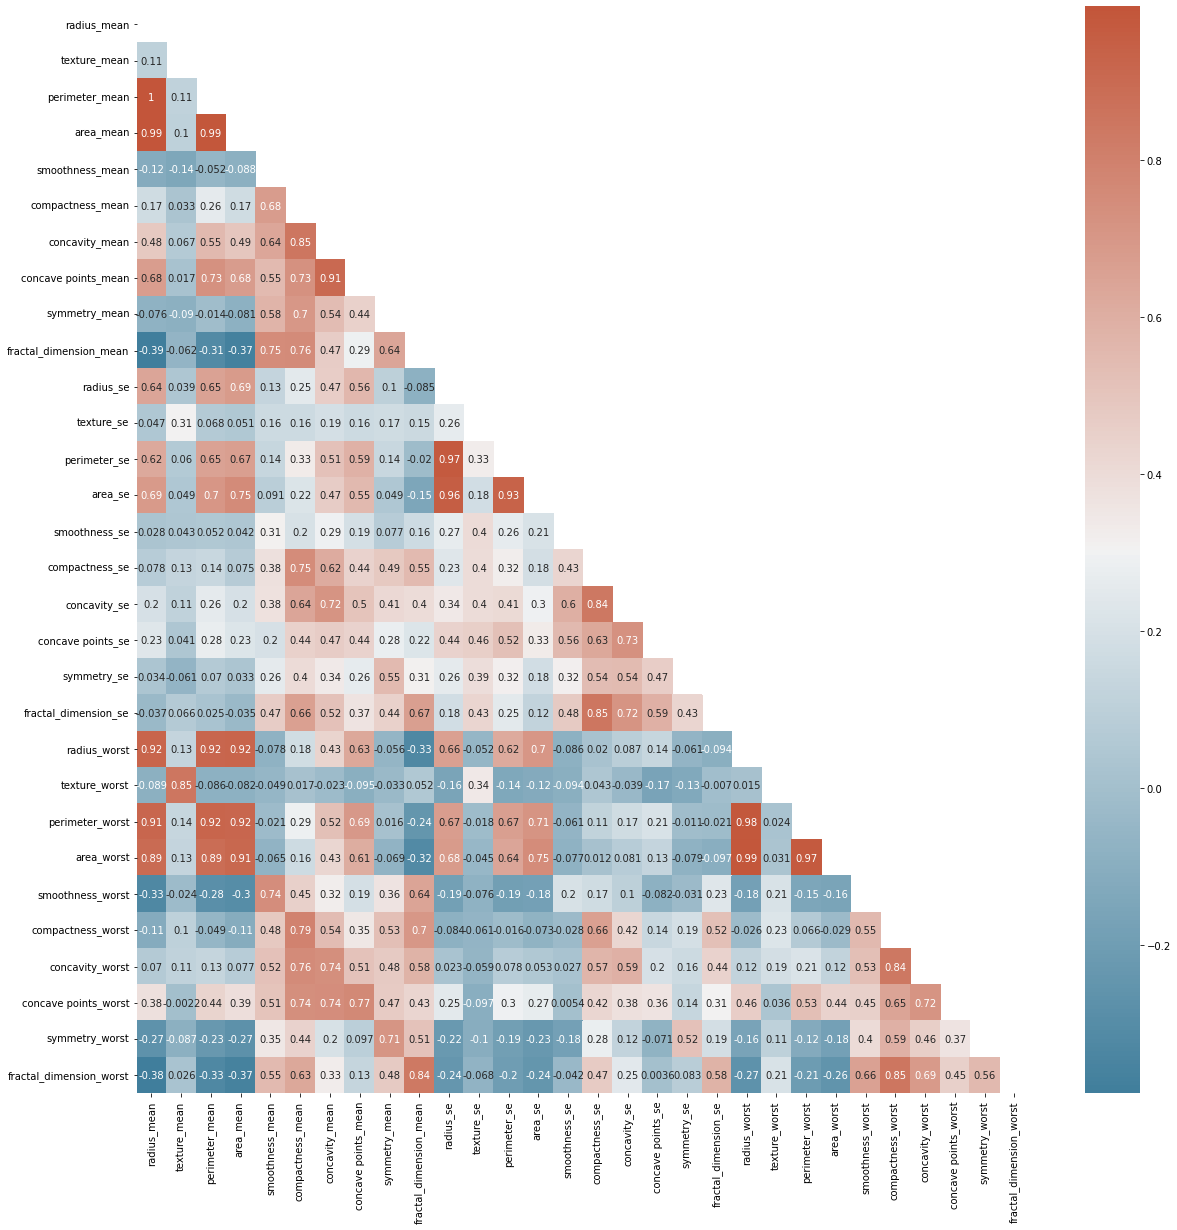

In [ ]:
correlation(df_m)


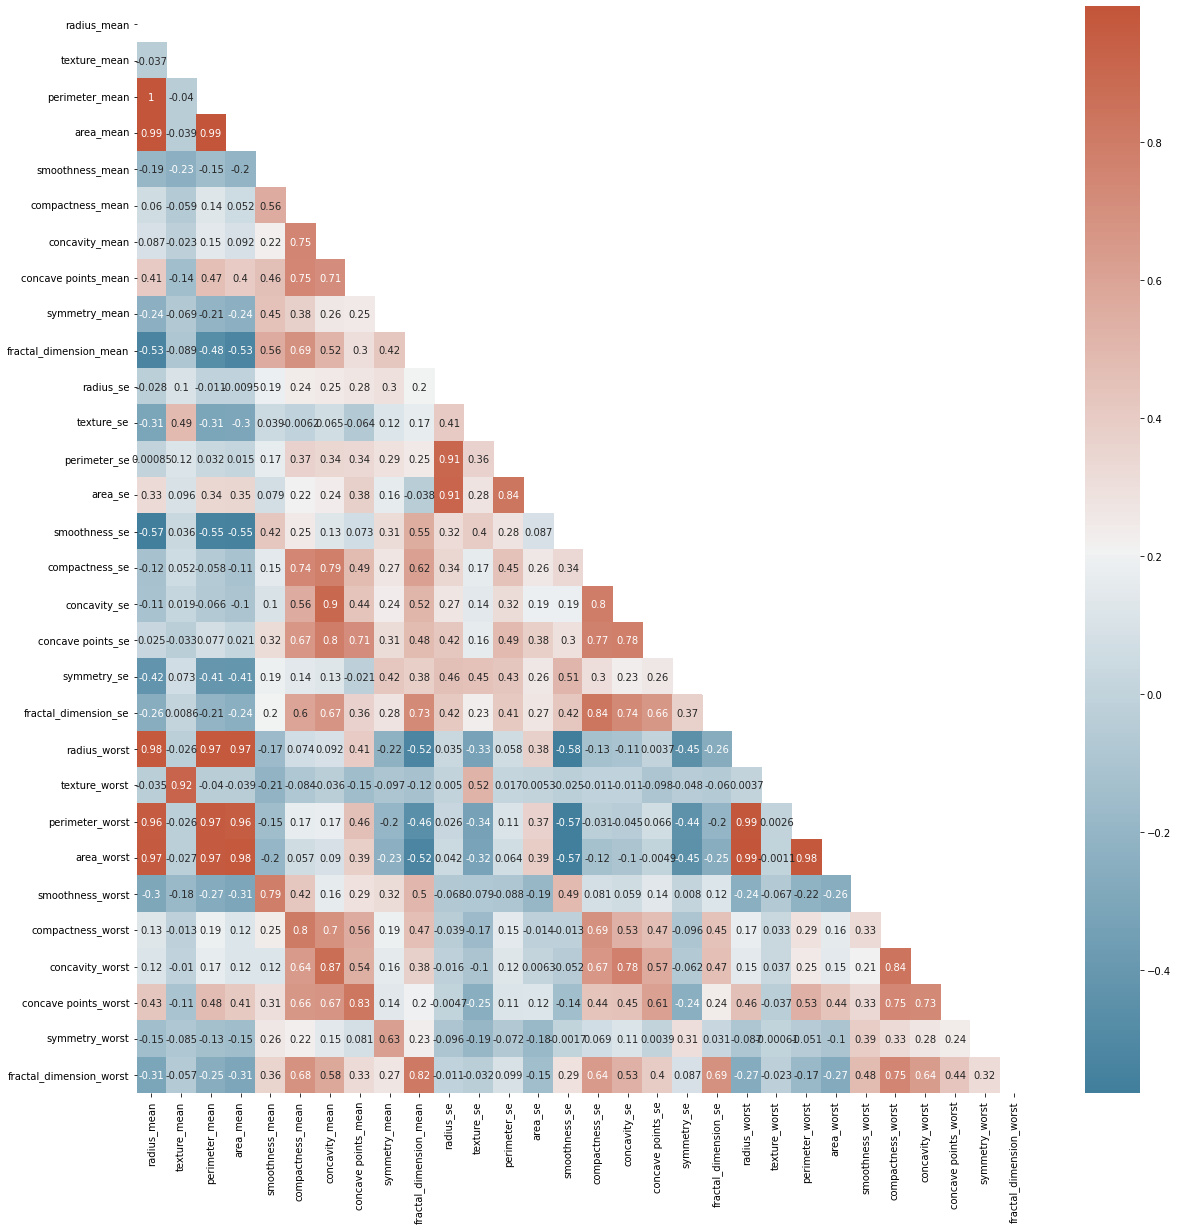

In [ ]:
correlation(df_B)

We can see features that have strong correlations with each other. 

The correlations seem to be similar for both classifications. In example, "radius_worst" has a very strong positive correlation with "perimeter_worst" and "area_worst" in both classification types

# Data Augmentation:

To balance our data we decided to augment it. To do so, we implemented a VAE model as we learned in class, which we will use to generate new samples of type "M". After performing statistical and visual tests to ensure the new samples are valid and have the same charasteristics of the original samples, we will add them to our dataset and then train on the augmented data.

**VAE Model**

The following figure represents our model architecture: 






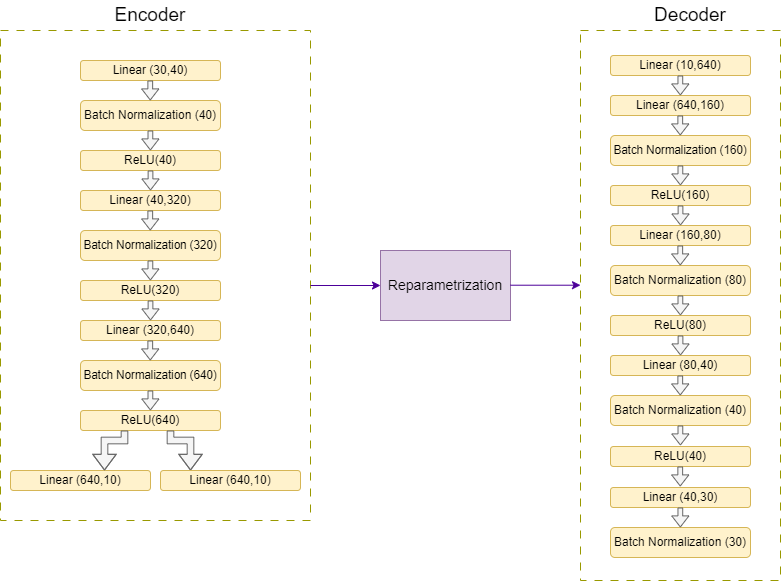



---


**VAE Encoder:**

The encoder consists of 3 blocks, each of them contains 3 stages:
* Stage 1 - A fully-connected linear layer, that increases the number of channels.
* Stage 2 - BatchNorm1d function to normalize the vector.
* Stage 3 - ReLU activation function, zeroes out negative values in the vector.

The number of output channels in each layer were determined according to different runs and the analysis of their results.

After the 3 blocks, we apply a fully-connected layer that outputs the latent vector.

We do it twice, one to sample the mean of the latent space, and one to sample the variance.

In [ ]:
class Encoder(nn.Module):
    def __init__(self, in_channels, num_hiddens=40, latent=10):
        super(Encoder, self).__init__()
        self.num_hiddens = num_hiddens
        self.latent = latent

        self.block1 = nn.Sequential(nn.Linear(in_channels,num_hiddens),
                                    nn.BatchNorm1d(num_hiddens),
                                    nn.ReLU())
        
        self.block2 = nn.Sequential(nn.Linear(num_hiddens, num_hiddens*8),
                                    nn.BatchNorm1d(num_hiddens*8),
                                    nn.ReLU())
        
        self.block3 = nn.Sequential(nn.Linear(num_hiddens*8, num_hiddens*16),
                                    nn.BatchNorm1d(num_hiddens*16),
                                    nn.ReLU())
        
        self.fc_mu = nn.Linear(num_hiddens*16,latent)    
        self.fc_logvar = nn.Linear(num_hiddens*16,latent) 

    def forward(self, inputs):
        x = self.block1(inputs)
        x = self.block2(x)
        x = self.block3(x)
        mu = self.fc_mu(x)
        logvar= self.fc_logvar(x)
        return mu, logvar 

**VAE Decoder:**

The decoder consists of four blocks with the same stages as in the encoder, the difference is that this model works in the opposite direction, first it uses fully-connected layer to map from the latent space to the last output channel size of the encoder (before compressing to the latent space) and then compresses the information and transfers it to its original size.

 

In [ ]:
class Decoder(nn.Module):
    def __init__(self, in_channels,out_channels, num_hiddens,latent):
        super(Decoder, self).__init__()
        self.num_hiddens = num_hiddens
        self.in_channels = in_channels
        
        self.fc_dec = nn.Linear(latent,in_channels) 

        self.block1 = nn.Sequential(nn.Linear(in_channels,num_hiddens//4),
                                    nn.BatchNorm1d(num_hiddens // 4),
                                    nn.ReLU())
        
        self.block2 = nn.Sequential(nn.Linear(num_hiddens//4,num_hiddens//8),
                                    nn.BatchNorm1d(num_hiddens // 8),
                                    nn.ReLU())

        self.block3 = nn.Sequential(nn.Linear(num_hiddens//8,num_hiddens//16),
                                    nn.BatchNorm1d(num_hiddens // 16),
                                    nn.ReLU())
        
        self.block4 = nn.Sequential(nn.Linear(num_hiddens // 16,out_channels),
                                    nn.BatchNorm1d(out_channels)
                                    )

    def forward(self, inputs):
        x = self.fc_dec(inputs)
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        x_rec = self.block4(x)
        return x_rec

**VAE Model:**

The VAE model uses the encoder and decoder to reconstruct information, and can be used to generate new information by sampling vectors from the latent space and using only the decoder.
This model is based on what we learned in class and contains the functions: reparameterize, weight_init, forward.

The model first encodes the data using the encoder, then it uses the recieved samples of the mean and variance to reparametrize the latent vector. After that the reparametrized latent is fed into the decoder to output the reconstructed data.



In [ ]:
class VAE(nn.Module):
    def __init__(self, enc_in_chnl,enc_num_hidden,dec_in_chnl,dec_out_channels,dec_num_hidden,latent):
        super(VAE, self).__init__()
        self.encode = Encoder(in_channels=enc_in_chnl, num_hiddens=enc_num_hidden,latent = latent)
        self.decode = Decoder(in_channels=dec_in_chnl,out_channels=dec_out_channels, num_hiddens=dec_num_hidden,latent = latent)

    # --- Reparametrization --
    def reparametrize(self, mu, logvar):
      std = torch.exp(0.5 * logvar)
      eps = torch.randn_like(std)
      return eps.mul(std).add_(mu)

    # --- Initialize Weights --
    def weight_init(self, mean, std):
        for m in self._modules:
            if isinstance(m, nn.ConvTranspose2d) or isinstance(m, nn.Conv2d):
                m.weight.data.normal_(mean, std)
                m.bias.data.zero_()

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparametrize(mu, logvar)
        x_rec = self.decode(z)
        return x_rec , mu, logvar

**VAE Loss Function:**

As we learned in class, the loss function should consist of the reconstruction loss and a beta enhanced KLD loss. We concluded from Assignment 4 that the value of beta affects:

A.
 Appropriate information transfer between the encoder and the decoder (the reconstruction is better) - achieved by a small beta.
 
B. Creating new information with the help of the latent vector (better generative capabilities) - achieved by a large beta.

Note that section A comes at the expense of section B and vice-versa.


Suprisingly, we found that using a relatively small beta in our loss function yielded the best results.

We tested multiple beta values, and saw that for larger betas the results were statistically worse, and all the generated information was too close to the mean. We believe that by focusing too much on the KLD loss the results were too close to the average and didn't have the behaviour of the original data.
Using a small beta ensures there is a slight deviation from the average and better variation of the generated data.

We chose the MSE function to estimate the reconstruction loss.




In [ ]:
beta = 0.5
def vae_loss(x_recon, x, mu, logvar):
    recon_loss = nn.functional.mse_loss( x_recon, x, reduction='sum')
    KLD = 0.5 * torch.sum(logvar.exp() - logvar - 1 + mu.pow(2))
    return recon_loss + beta*KLD

Train, Validation split and Normalization:

In [ ]:
df_m2 = shuffle(df_m)
df_m2.pop("diagnosis")  
train, val = df_m2[50:].to_numpy(dtype=np.float32), df_m2[:50].to_numpy(dtype=np.float32)
scaler = StandardScaler()
train = scaler.fit_transform(train)
val = scaler.transform(val)

**Training function**

The function "train_vae" perform training of the model based on given parameters. We use the Adam optimizer and our customized loss criterion. 

In [ ]:
def train_vae(num_epochs,batch_size,learning_rate,model,train,val):
    train_losses = []
    validations_losses = []
    # --- Adam optimizer ---
    optimizer = optim.Adam(model.parameters(),lr=learning_rate)
    model.train() 
    for epoch in range(num_epochs):
      train_loss = 0
      iters = 0
      # --- Shuffle train data ---
      train = shuffle(train, random_state=0)
      for i in range(0, train.shape[0], batch_size):
          if (i + batch_size) > train.shape[0]:
              break
          optimizer.zero_grad()
          xt = torch.Tensor(train[i : i + batch_size])
          # ===================forward=====================
          # --- Compute prediction logit ---
          xt_recon, mu, logvar = model(xt)               
          # --- Compute loss ---
          loss = vae_loss(xt_recon, xt,mu,logvar)          
          train_loss += loss.item()
          # ===================backward====================
          loss.backward()
          optimizer.step()
          iters += 1
        # ===================log========================
      print(f'==== Epoch: {epoch} ====')
      print(f'Train loss: {(train_loss/ (iters*batch_size)):.4f}')
      train_losses.append(train_loss/(iters*batch_size))


      # --- Validation ---
      with torch.no_grad():
        model.eval() 
        iters = 0
        val_loss = 0
        # --- Shuffle validation data --
        val = shuffle(val, random_state=0)
        for i in range(0, val.shape[0], batch_size):
            if (i + batch_size) > val.shape[0]:
                break
            xv = torch.Tensor(val[i : i + batch_size])
            # ===================forward=====================
            # --- Compute prediction logit ---
            xv_recon, mu, logvar = model(xv)
            # --- Compute loss ---     
            loss = vae_loss(xv_recon,xv, mu, logvar)    
            val_loss += loss.item()
            iters += 1 

      print(f'Validation Loss: {(val_loss/ (iters*batch_size)):.4f}')
      validations_losses.append(val_loss/(iters*batch_size))

    return train_losses,validations_losses

Function to plot the learning curves:

In [ ]:
def plot_learning_curve(train_losses,validations_losses):
    """
    Plot the learning curve.
    """
    plt.title("Learning Curve: Loss per epoch")
    plt.plot(range(len(train_losses)), train_losses, label="Train")
    plt.xlabel("Epochs")
    plt.ylabel("Loss")
    plt.legend(loc='best')
    plt.show()

    plt.title("Learning Curve: Loss per Iteration")
    plt.plot(range(len(validations_losses)), validations_losses, label="Validation")
    plt.xlabel("Epochs")
    plt.ylabel("Loss")
    plt.legend(loc='best')
    plt.show()

Configuring VAE training parameters

In [ ]:
learning_rate = 0.0001
batch_size = 10
num_epochs = 100

# --- VAE Class inputs --
enc_in_chnl = 30
enc_num_hidden = 40    
dec_in_chnl = 640       
dec_num_hidden = 640  
dec_out_channels = 30
latent = 10

Creating the VAE model and training:

In [ ]:
model_vae = VAE(enc_in_chnl,enc_num_hidden,dec_in_chnl,dec_out_channels,dec_num_hidden,latent)
model_vae.weight_init(mean=0, std=0.02)

In [ ]:
train_losses,val_losses= train_vae(num_epochs,batch_size,learning_rate,model_vae,train,val)

**We omitted the output since it was too large, the final 10 epochs are:**

==== Epoch: 90 ====

Train loss: 8.9820

Validation Loss: 12.9026

==== Epoch: 91 ====

Train loss: 8.8361

Validation Loss: 12.5206

==== Epoch: 92 ====

Train loss: 9.0594

Validation Loss: 12.5407

==== Epoch: 93 ====

Train loss: 9.0208

Validation Loss: 12.6466

==== Epoch: 94 ====

Train loss: 8.8496

Validation Loss: 12.5638

==== Epoch: 95 ====

Train loss: 8.8801

Validation Loss: 12.6299

==== Epoch: 96 ====

Train loss: 9.1720

Validation Loss: 12.5089

==== Epoch: 97 ====

Train loss: 8.9747

Validation Loss: 12.7032

==== Epoch: 98 ====

Train loss: 8.7025

Validation Loss: 11.8059

==== Epoch: 99 ====

Train loss: 8.6222

Validation Loss: 12.2583

**Learning Curves**

Observing the graphs below, we see the train loss value decreases as the number of epochs increases. Validation loss values also introduces similar behaviour, meaning there is no indication of overfitting during the run.

Note that we start plotting after the first epoch, because it has values too high for the plot.

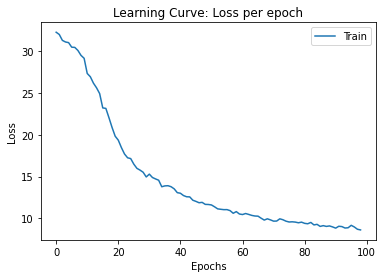

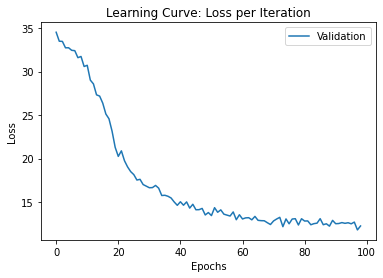

In [ ]:
plot_learning_curve(train_losses[1:],val_losses[1:])

**Generating new samples**

The function "generate_samples" genartes new data samples of type M.
Using our VAE model we generate the desired number of samples in the latent space and apply the decoder to create the new data, then we concat it with the original data.
After concating we ensure there are no duplicate rows, meaning all generated data is unique.


In [ ]:
def generate_samples(origin_df,model,num_samples,latent,scaler):
  df_copy = origin_df.copy()
  model.eval()
  dummy = torch.empty([num_samples,latent])
  z = torch.randn_like(dummy) # randon N(0,1)
  # --- insert the random noise to the decoder to create new samples ---
  samples = model_vae.decode(z) 
  # --- do inverse transform on sample ---
  samples=scaler.inverse_transform(samples.detach().numpy()) 
  # --- map samples to DataFrame ---
  cols = list(df_copy.columns)[1:]
  # --- Create DataFrame from the new samples ---
  new_data = pd.DataFrame(samples,columns = cols)
  new_data.insert(loc=0,column='diagnosis',value=0)
  # ---  concat df_copy and new_data  ---
  new_df = pd.concat([df_copy,new_data], ignore_index=True)
  print(f"found {new_df.duplicated().sum()} duplicates")
  return new_df

new_df_m = generate_samples(origin_df=df_m,model=model_vae,num_samples=145,latent=latent,scaler=scaler)
new_df_m

found 0 duplicates


,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,0,17.990000,10.380000,122.800000,1001.000000,0.118400,0.277600,0.300100,0.147100,0.241900,...,25.380000,17.330000,184.600000,2019.000000,0.162200,0.665600,0.711900,0.265400,0.460100,0.118900
1,0,20.570000,17.770000,132.900000,1326.000000,0.084740,0.078640,0.086900,0.070170,0.181200,...,24.990000,23.410000,158.800000,1956.000000,0.123800,0.186600,0.241600,0.186000,0.275000,0.089020
2,0,19.690000,21.250000,130.000000,1203.000000,0.109600,0.159900,0.197400,0.127900,0.206900,...,23.570000,25.530000,152.500000,1709.000000,0.144400,0.424500,0.450400,0.243000,0.361300,0.087580
3,0,11.420000,20.380000,77.580000,386.100000,0.142500,0.283900,0.241400,0.105200,0.259700,...,14.910000,26.500000,98.870000,567.700000,0.209800,0.866300,0.686900,0.257500,0.663800,0.173000
4,0,20.290000,14.340000,135.100000,1297.000000,0.100300,0.132800,0.198000,0.104300,0.180900,...,22.540000,16.670000,152.200000,1575.000000,0.137400,0.205000,0.400000,0.162500,0.236400,0.076780
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
352,0,16.769636,24.027534,108.247948,849.512634,0.090873,0.087962,0.092024,0.056583,0.183325,...,18.869078,31.181328,125.628906,1237.937012,0.134106,0.264526,0.292851,0.137380,0.329057,0.073355
353,0,15.672729,19.194605,101.089371,786.082581,0.110508,0.136506,0.138572,0.080642,0.195365,...,18.683302,28.288671,126.924469,1136.064575,0.160960,0.372111,0.415782,0.185006,0.338824,0.097857
354,0,16.227388,21.586706,110.260216,798.323608,0.115733,0.208609,0.242289,0.107996,0.207584,...,19.208923,29.168510,137.957458,1173.386841,0.163555,0.536571,0.661006,0.206364,0.364762,0.110924
355,0,16.583569,23.168716,103.280151,768.181580,0.104228,0.126861,0.139883,0.075306,0.189250,...,19.265722,33.168903,122.718018,1239.630859,0.157085,0.373417,0.432792,0.169758,0.339747,0.091347


**Testing the New Data**

After augmenting the dataset, we verify that the new created data is statistically appropriate, I.E that the statistical behaviour of the new data matches the behaviour of the original data. To do so we created the function "test prob".

This function performs two statistical tests between the two datasets given:  Mann–Whitney U test and the Kolmogorov–Smirnov test.

 Essentialy for both tests the Null hypothesis: $H_{0}$ is that both populations are from the same distribution. The alternative:  $H_{1}$ is that they are not. In order to reject $H_{0}$ we require p-value to be less than 0.05. 
 
 The function prints a table, classifying each feature's $H_{0}$ as "Rejected", "Not Rejected" or "Not Clear" if only one test cannot reject the null hypothesis. Then the function returns a list of the features that are not "Not Rejected".

In [ ]:
def test_prob(df ,df_new):
  results = []
  mw_p_values = []
  ks_p_values = []
  features_to_inspect = []
  # --- Iterate all features except for Diagnosis ---
  for col in cols[1:]:
    # --- Perform the statistical tests ---
    stat_mw, p_value_mw = mannwhitneyu(df[col], df_new[col])
    stat_ks, p_value_ks = kstest(df[col], df_new[col])
    # --- Analyze results ---
    if(p_value_mw > 0.05 and p_value_ks > 0.05):
      results.append("Not Rejected")
    elif (p_value_mw < 0.05 and p_value_ks <0.05):
      results.append("Rejected")
      features_to_inspect.append(col) 
    else:
      results.append("Not Clear")
      features_to_inspect.append(col)
    mw_p_values.append(p_value_mw)
    ks_p_values.append(p_value_ks)
  # --- Create table ---
  prob_table = pd.concat([pd.Series(cols[1:]), pd.Series(mw_p_values),pd.Series(ks_p_values),pd.Series(results)], axis=1)
  prob_table = prob_table.rename(columns = {0 : 'Feature', 1 : 'Mann–Whitney U test',2:"Kolmogorov–Smirnov test",3:"H0 Conclusion"})
  display(prob_table)
  # --- Print features that need further inspection  ---
  print(f"There are {len(features_to_inspect)} features to inspect")
  for i,feat in enumerate(features_to_inspect):
    print(f"{i+1}). {feat}")
  return features_to_inspect

The function "compare_boxplots" plots a feature's boxplot from the new and original data side-by-side for visual analysis of the augmentation results.

In [ ]:
def compare_boxplots(original_data, new_data, feature,Dtype,ax):
  origin = pd.DataFrame(original_data[feature])
  origin["indicator"]= f"Original_{Dtype}"
  new = pd.DataFrame(new_data[feature])
  new["indicator"]= f"New_{Dtype}"
  test = pd.concat([origin,new])
  sns.boxplot(data=test,x="indicator",y=feature,ax=ax)

def compare_all_boxplots(original_data, new_data, features,Dtype):
  plt.figure(figsize=(30,30))
  ind=0
  for i in range(5):
    for j in range(6):
      if ind<len(features):
        ax_new = plt.subplot(5,6,ind+1)
        compare_boxplots(original_data,new_data,features[ind],Dtype,ax_new)
        ind +=1

Performing the statistical tests as we described:

In [ ]:
features_to_inspect_m = test_prob(df_m ,new_df_m)

,Feature,Mann–Whitney U test,Kolmogorov–Smirnov test,H0 Conclusion
0,radius_mean,0.693790,0.941041,Not Rejected
1,texture_mean,0.709039,0.996257,Not Rejected
2,perimeter_mean,0.747462,0.980985,Not Rejected
3,area_mean,0.788146,0.992613,Not Rejected
4,smoothness_mean,0.801163,0.999983,Not Rejected
5,compactness_mean,0.637465,0.920510,Not Rejected
6,concavity_mean,0.564122,0.984991,Not Rejected
7,concave points_mean,0.604329,0.912960,Not Rejected
8,symmetry_mean,0.943447,0.983710,Not Rejected
9,fractal_dimension_mean,0.834354,0.995089,Not Rejected


There are 0 features to inspect


**All features passed both statistical tests!**

Since we have no problematic features, we visually compare all boxplots to ensure the behaviour of the new samples is as we expected:

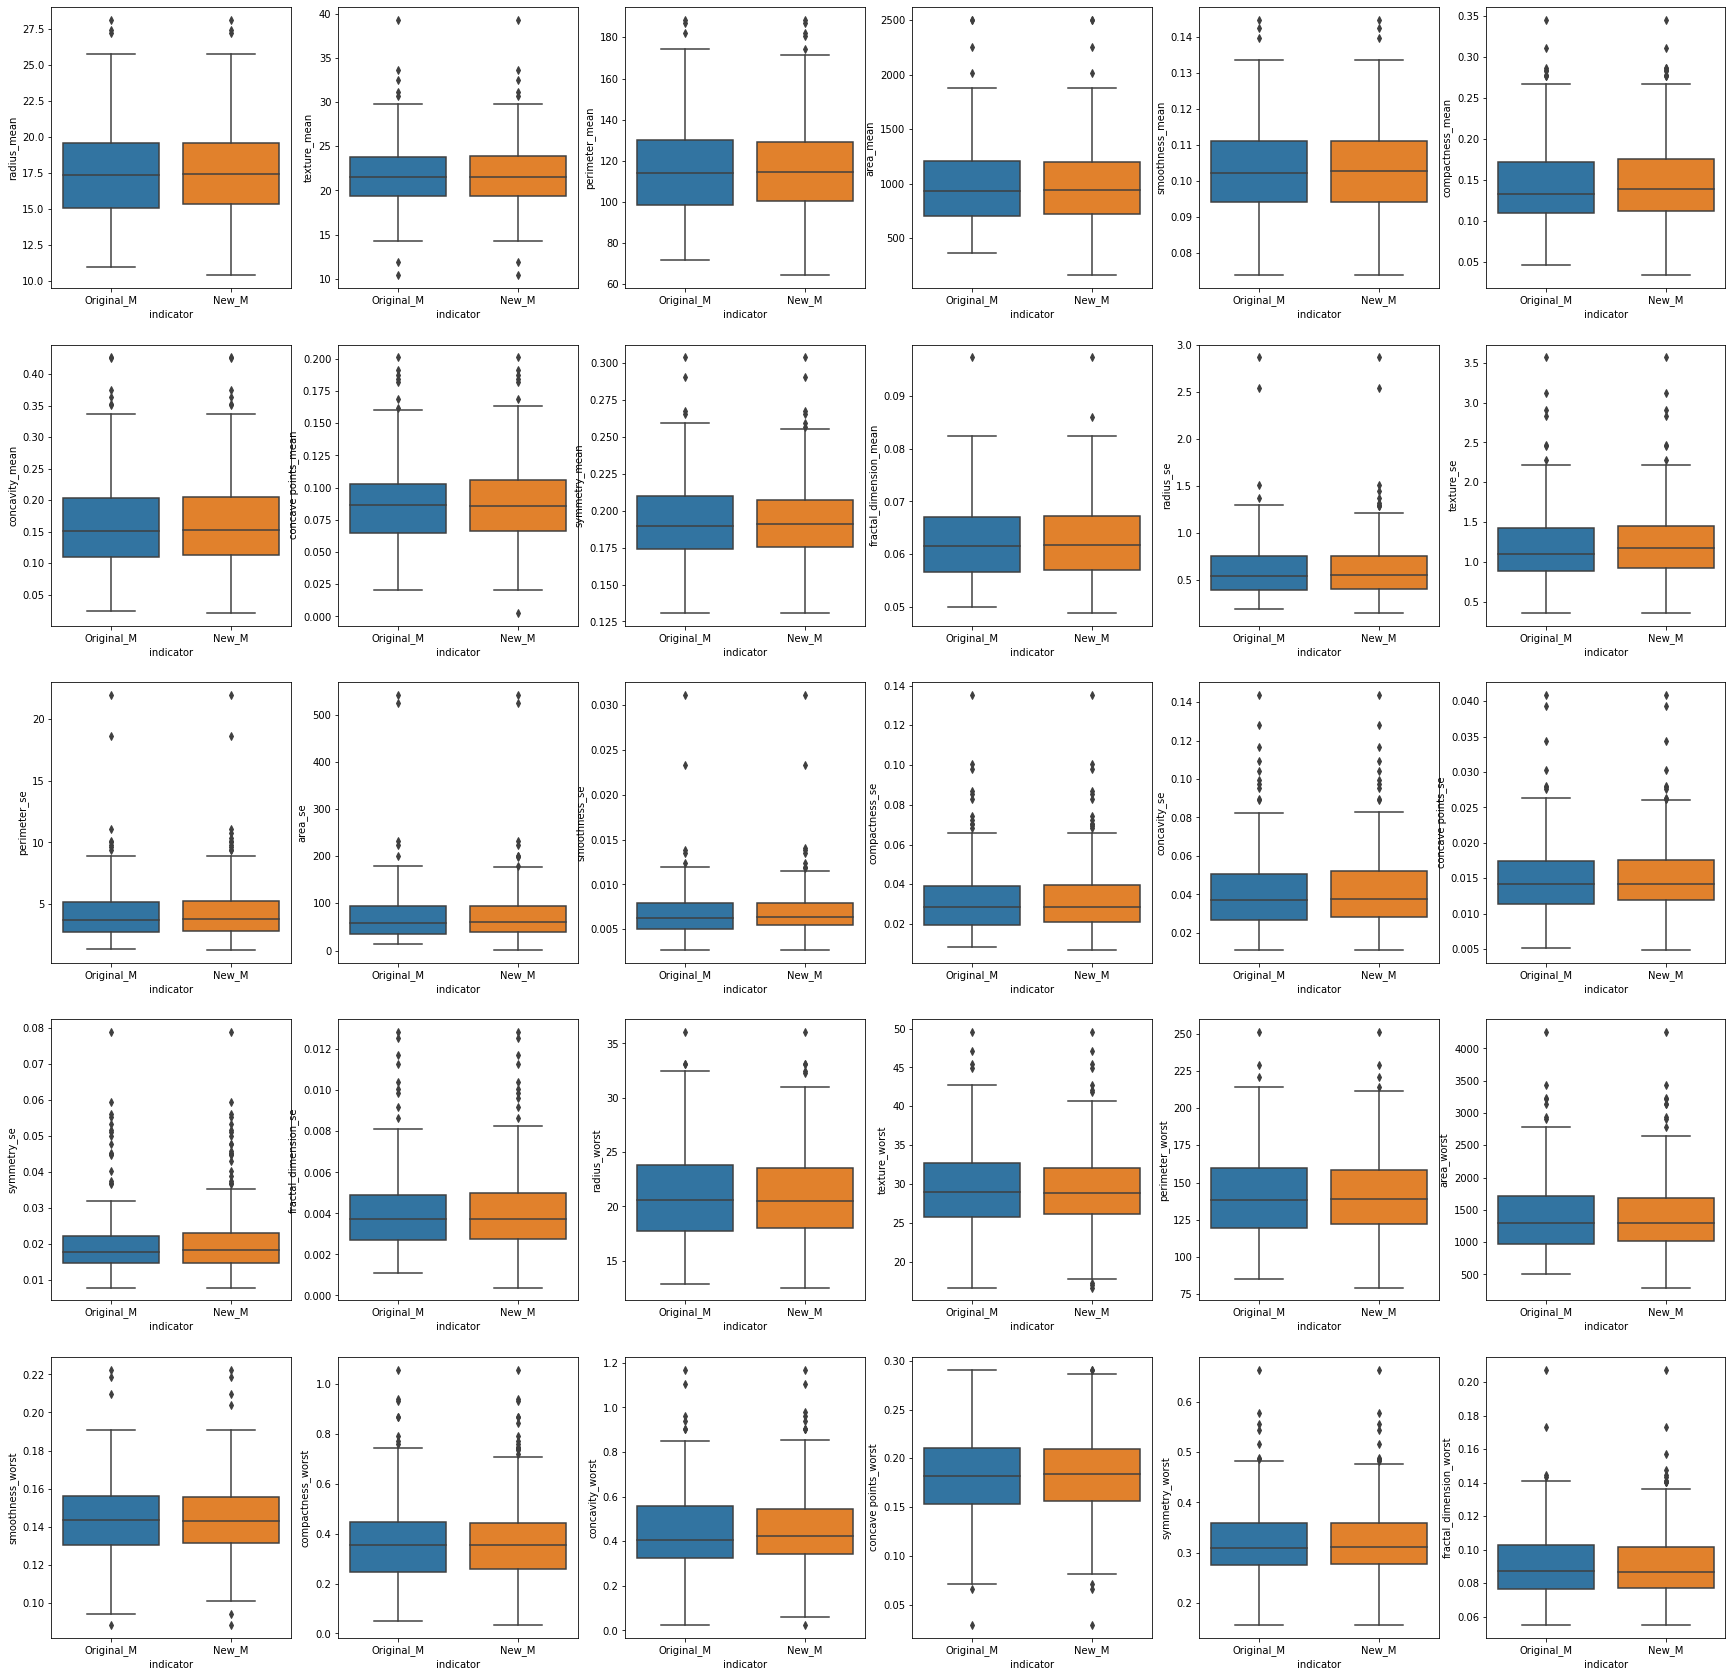

In [ ]:
compare_all_boxplots(original_data=df_m,new_data=new_df_m,features=cols[1:],Dtype='M')

Visually, the original and new data appear to have the same behaviour. The median is preserved, as well as the boxes lengths. Even the outliers appear to be similar and with the same trend.

**Overall the VAE model appeared to perform very well in terms of augmenting our data.**



---



**Comparing to Existing Augmentation methods (Tabular GAN):**

We compare our VAE results to a Tabular GAN for data augmentation. Info about it can be found in references [2] and [3].


The function "augment_data_GAN" creates new samples of data using the Tabular GAN, note that GANGenerator creates a varying amount of data samples, so we used a loop to ensure it creates sufficient amount of them.

In [ ]:
def augment_data_GAN(origin_df,Dtype,num_to_generate=145):
  Dtype_dict = {"M":0, "B":1}
  # --- Our dataset can be loaded from sklearn, this format works better with GANGenerator ---
  dataset = sklearn.datasets.load_breast_cancer()  
  # --- Filtering the data type to generate (M\B) ---
  data = dataset.data[dataset['target'] == Dtype_dict[Dtype]]
  target  = dataset.target[dataset['target'] ==Dtype_dict[Dtype]]

  # --- Training the GAN until it generates num_to_generate samples ---
  X_train, X_test, y_train, y_test = sklearn.model_selection.train_test_split(
      pd.DataFrame(data), pd.DataFrame(target, columns=["target"]), test_size=0.33, random_state = randint(0,7000))
  new_data = pd.DataFrame()
  while (len(new_data)<num_to_generate):
    temp_data, _ = GANGenerator(gen_x_times=50).generate_data_pipe(X_train, y_train, X_test,only_generated_data=True )
    new_data = pd.concat([new_data,temp_data], ignore_index=True)

  # ---  Concat df_copy and new_data  ---
  df_copy = origin_df.copy()
  new_data = new_data.sample(n=num_to_generate)
  cols = list(df_copy.columns)[1:]
  new_data = new_data.set_axis(cols, axis="columns")
  new_data.insert(loc=0,column='diagnosis',value=0)
  new_df = pd.concat([df_copy,new_data], ignore_index=True)
  # ---  Check for Duplicates  ---
  print(f"found {new_df.duplicated().sum()} duplicates")
  return new_df

Creating samples using the GAN and applying statistical tests:

In [ ]:
new_df_m_tabgan = augment_data_GAN(df_m,"M")
features_to_inspect_m = test_prob(df_m ,new_df_m_tabgan)

Fitting CTGAN transformers for each column:   0%|          | 0/31 [00:00<?, ?it/s]

Training CTGAN, epochs::   0%|          | 0/500 [00:00<?, ?it/s]

Fitting CTGAN transformers for each column:   0%|          | 0/31 [00:00<?, ?it/s]

Training CTGAN, epochs::   0%|          | 0/500 [00:00<?, ?it/s]

found 0 duplicates


,Feature,Mann–Whitney U test,Kolmogorov–Smirnov test,H0 Conclusion
0,radius_mean,0.506510,0.945425,Not Rejected
1,texture_mean,0.200810,0.306844,Not Rejected
2,perimeter_mean,0.288017,0.371400,Not Rejected
3,area_mean,0.271594,0.655936,Not Rejected
4,smoothness_mean,0.185652,0.327816,Not Rejected
5,compactness_mean,0.759078,0.997602,Not Rejected
6,concavity_mean,0.086947,0.283495,Not Rejected
7,concave points_mean,0.164208,0.194536,Not Rejected
8,symmetry_mean,0.285155,0.497251,Not Rejected
9,fractal_dimension_mean,0.064099,0.084990,Not Rejected


There are 6 features to inspect
1). texture_se
2). smoothness_se
3). compactness_se
4). concave points_se
5). compactness_worst
6). symmetry_worst


Clearly, the GAN performs worse than our VAE, it has multiple "Rejected" and "Not Clear" features whereas our VAE created samples such that all features are "Not Rejected". 

The GAN results are similar across multiple runs we made, we didn't achieve similar results to our VAE by using the GAN.

Reviewing boxplots of the problematic features of GAN:

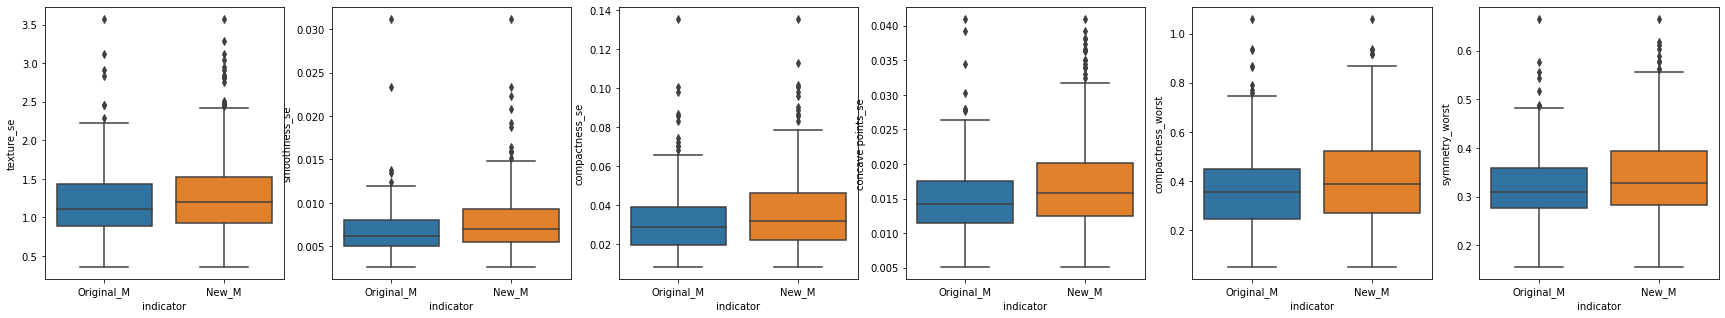

In [ ]:
fig, (axs) = plt.subplots(1,len(features_to_inspect_m),figsize=(30,5))
for i,feature in enumerate(features_to_inspect_m):
  compare_boxplots(original_data=df_m, new_data=new_df_m_tabgan, feature=feature,Dtype="M",ax = axs[i])

There is indeed a noticeable  difference between the boxplots.

**After verifying our VAE generated statistically appropriate samples and even performs better than the GANGenerator, we confidently use it to balance the data and train our model on the augmented data.**

# Model and training:

Since we augmented the "M" classification samples, we concat it with the original "B" classification samples to obtain the whole new augmented dataset. We then shuffle it and split to features (X) and target (y).

In [ ]:
new_df_concat = pd.concat([df_B,new_df_m], ignore_index=True)
X = new_df_concat
X = shuffle(X, random_state=0)
y= X.pop('diagnosis')



Train-test-validation splitting and Normalization:

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=100)
scaler = StandardScaler()

X_train, X_val = X_train[71:],X_train[:71]
y_train, y_val = y_train[71:].to_numpy(dtype=np.int32),y_train[:71].to_numpy(dtype=np.int32)

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
X_val = scaler.transform(X_val)


**Model Architecture**

The model architecture that yielded the best results is:

(comparison between our different tested models is provided in the next section) 



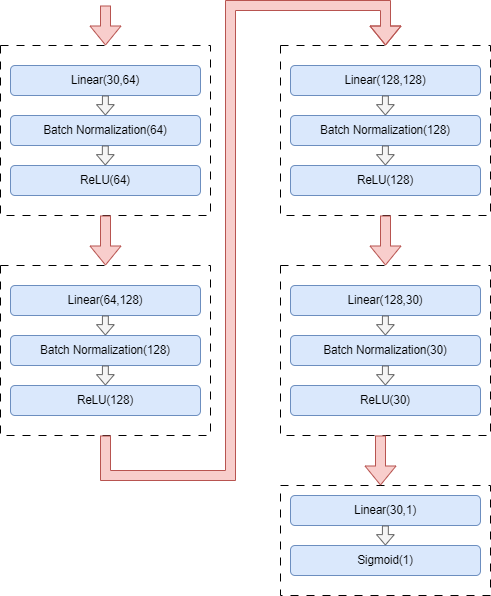

The model consists of 5 blocks. The first 4 blocks each contains 3 stages:
* Stage 1 - A fully-connected linear layer.
* Stage 2 - BatchNorm1d function to normalize the vector.
* Stage 3 - ReLU activation function, zeroes out negative values in the vector.

The number of output channels in each layer were determined according to different runs and the analysis of their results.

The final block is a fully-connected linear layer mapping to a single channel and a final activation function- Sigmoid(), which yields values in the range (0,1). We then round those values to obtain the classification.

In [ ]:
class CancerDetectionModel(nn.Module):
  def __init__(self, num_hiddens,input_features=30):
        super(CancerDetectionModel, self).__init__()

        self.block1 = nn.Sequential(nn.Linear(input_features,num_hiddens),
                                    nn.BatchNorm1d(num_hiddens),
                                    nn.ReLU())
        self.block2 = nn.Sequential(nn.Linear(num_hiddens,num_hiddens*2),
                                    nn.BatchNorm1d(num_hiddens*2),
                                    nn.ReLU())
        self.block3 = nn.Sequential(nn.Linear(num_hiddens*2,num_hiddens*2),
                                    nn.BatchNorm1d(num_hiddens*2),
                                    nn.ReLU())
        self.block4 = nn.Sequential(nn.Linear(num_hiddens*2,input_features),
                                    nn.BatchNorm1d(input_features),
                                    nn.ReLU())
        self.final_block = nn.Sequential(nn.Linear(input_features,1),
                                    nn.Sigmoid())
  def forward(self, inputs):
    x = self.block1(inputs)
    x = self.block2(x)
    x = self.block3(x)
    x = self.block4(x)
    y_pred = self.final_block(x)
    return y_pred.flatten()

**Accuracy function**

The function "accuracy" rounds the predicted y_pred vector. Since the output of Sigmoid() is between 0-1, the rounded prediction is either 0 or 1 and we compare it with the original classification to obtain the accuracy.

In [ ]:
def accuracy(y_pred, y):
    y_pred = torch.round(y_pred)
    correct_results_sum = (y_pred == y).sum().float()
    acc = correct_results_sum / y.shape[0]
    return acc *100

**Train and loss**

Our train function uses Adam as it's optimizer, we chose Binary-Cross-Entropy as the loss criterion since we are performing a binary classification. The train function recieves the data, model and parameters such as learning rate and batch size, performs training and calculates loss and accuracy for both the train and validation sets.

In [ ]:
def train(num_epochs,batch_size,learning_rate,model,X_train,y_train,X_val,y_val):
    train_losses = []
    validations_losses = []
    # ---  Using BCE Loss  ---
    criterion = nn.BCELoss()
    # ---  Adam optimizer ---
    optimizer = optim.Adam(model.parameters(),lr=learning_rate)
    model.train() 
    for epoch in range(num_epochs):
      if epoch>0:
        train_loss = 0
        train_accuracy = 0
        iters = 0
        # ---  Shuffle train data  ---
        X_train, y_train = shuffle(X_train, y_train, random_state=0)
        for i in range(0, X_train.shape[0], batch_size):
            if (i + batch_size) > X_train.shape[0]:
                break
            optimizer.zero_grad()
            xt = torch.Tensor(X_train[i : i + batch_size])
            yt = torch.Tensor(y_train[i : (i + batch_size)]).float()
            # ===================forward=====================
            # ---  Compute prediction logit  ---
            y_pred = model(xt)    
            # ---  Compute loss  ---   
            loss = criterion(y_pred, yt)  
            train_accuracy += accuracy(y_pred, yt)
            train_loss += loss.item()
            # ===================backward====================
            loss.backward()
            optimizer.step()
            iters += 1
        # ===================log========================
        print(f'==== Epoch: {epoch} ====')
        print(f'Train loss: {(train_loss / (iters*batch_size)):.4f}, Accuracy: {train_accuracy/iters:.2f}%')
        train_losses.append(train_loss /(iters*batch_size))

      # Validation set
      val_acc = 0
      iters = 0
      val_loss = 0
      X_val, y_val = shuffle(X_val, y_val, random_state=0)
      for i in range(0, X_val.shape[0], batch_size):
          if (i + batch_size) > X_val.shape[0]:
              break
          xv = torch.Tensor(X_val[i : i + batch_size])
          yv = torch.Tensor(y_val[i : i + batch_size]).float()
          # ===================forward=====================
          # ---  Compute prediction logit  ---
          yv_pred = model(xv)         
          # ---  Compute loss  ---     
          loss = criterion(yv_pred, yv)    
          val_loss += loss.item()
          val_acc += accuracy(yv_pred, yv)
          iters += 1 

      print(f'Validation Loss: {(val_loss/(iters*batch_size)):.4f}, Accuracy: {val_acc/iters:.2f}%')
      validations_losses.append(val_loss/(iters*batch_size))


    return train_losses,validations_losses

**Configuring model and training parameters**

Here we configure the training and model parametes, the following are the best-resulting parameters:

In [ ]:
num_epochs = 10
batch_size = 20
learning_rate = 0.001

model = CancerDetectionModel(num_hiddens= 64)

Training the model:

In [ ]:
train_losses,validations_losses = train(num_epochs,batch_size,learning_rate,model,X_train,y_train,X_val,y_val)

Validation Loss: 0.0328, Accuracy: 61.67%
==== Epoch: 1 ====
Train loss: 0.0206, Accuracy: 89.76%
Validation Loss: 0.0144, Accuracy: 93.33%
==== Epoch: 2 ====
Train loss: 0.0131, Accuracy: 94.29%
Validation Loss: 0.0099, Accuracy: 96.67%
==== Epoch: 3 ====
Train loss: 0.0094, Accuracy: 96.90%
Validation Loss: 0.0083, Accuracy: 96.67%
==== Epoch: 4 ====
Train loss: 0.0073, Accuracy: 97.14%
Validation Loss: 0.0075, Accuracy: 95.00%
==== Epoch: 5 ====
Train loss: 0.0064, Accuracy: 96.90%
Validation Loss: 0.0074, Accuracy: 96.67%
==== Epoch: 6 ====
Train loss: 0.0062, Accuracy: 96.67%
Validation Loss: 0.0059, Accuracy: 95.00%
==== Epoch: 7 ====
Train loss: 0.0059, Accuracy: 97.38%
Validation Loss: 0.0067, Accuracy: 95.00%
==== Epoch: 8 ====
Train loss: 0.0052, Accuracy: 96.43%
Validation Loss: 0.0066, Accuracy: 93.33%
==== Epoch: 9 ====
Train loss: 0.0047, Accuracy: 96.90%
Validation Loss: 0.0040, Accuracy: 95.00%


Plotting learning curves:

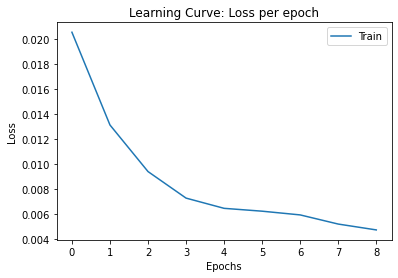

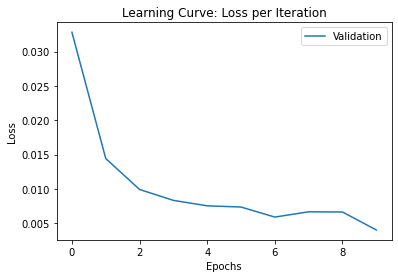

In [ ]:
plot_learning_curve(train_losses,validations_losses)

The learning curves look very good, both training and validation losses decrease.

## Test Results and Benchmarks

We evaluate our model using **Accuracy** and **F1 score**.

F1 score is a measure of test's accuracy. It is calculated from the precision and recall of the test. 
The precision is the number of true positive results divided by the number of all positive results, and the recall is the number of true positive results divided by the number of all samples that should have been identified as positive.

The formula for F1 score is:
$F1 = \frac{2\cdot TP}{2\cdot TP + FP + FN}$ 

Where TP=True Positive, FP = False Positive, FN = False Negative.

The more accurate the model, F1 approches closer to 1.

The function "testing" takes as parameters our trained model and the test set, performs predictions and outputs the accuracy, f1 score and confusion matrix.



In [ ]:
def testing(model,X_test,y_test):
    model.eval()
    xt = torch.Tensor(X_test)
    yt = torch.Tensor(y_test.to_numpy(dtype=np.int32)).float()
    # ---  Make prediction  ---
    yt_pred = model(xt)   
    # ---  Calculate accuracy  ---             
    acc = accuracy(yt_pred, yt)
    yt_pred = torch.round(yt_pred)
    # ---  Calculate F1 score  ---
    f1 = f1_score(yt.tolist(),yt_pred.tolist())
    print("*"*45)
    print("*********** CancerDetectionModel: ***********")
    print("*"*45)
    print(f"\nTest Accuracy: {acc:.2f}%, F1 score: {round(f1,3)}\n")
    # ---  Create and plot confusion matrix  ---
    conf_mat = confusion_matrix(y_test.tolist(),yt_pred.tolist())
    ticks = [0,1]
    sns.heatmap(conf_mat.T, square=True, annot=True, fmt='d', cbar=False, xticklabels=ticks, yticklabels=ticks)
    plt.title("Test Confusion Matrix - CancerDetectionModel")
    plt.xlabel('True label')
    plt.ylabel('Predicted label');
    return 

Our model achieves the following results:

*********************************************
*********** CancerDetectionModel: ***********
*********************************************

Test Accuracy: 98.60%, F1 score: 0.987



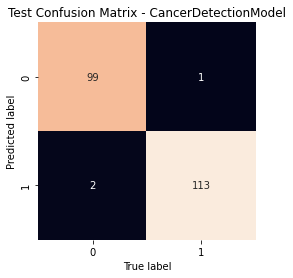

In [ ]:
testing(model,X_test,y_test)

# Performance Comparison

In this section we display the results we obtained using different parameters and architectures of the model that helped us in the process of achieving our optimal results.

 We also compare to two State-Of-The-Art classifiers - RandomForest and Naive-Bayes, and show our model surpassed them.

The following table summarizes **differnt models and parameters we tested** and their results:

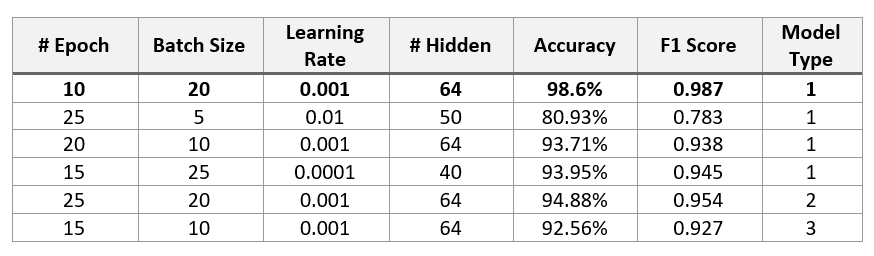

Model type 1 is the model we presented.

Model type 2 consists of 4 blocks instead of 5, each containing fully connected layer, normalization and ReLU activation. 
block 1: (#in_features,#hidden) , block 2: (#hidden,#hidden\*8) , block 3: (#hidden\*8,#in_features), block 4:(#in_features,1)

Model type 3 consists of 6 blocks instead of 4, each containing fully connected layer, normalization and ReLU activation. 
block 1: (#in_features,#hidden) , block 2: (#hidden,#hidden\*4) , block 3: (#hidden\*4,#hidden\*8), block 4:(#hidden\*8,#hidden\*2), block 5:(#hidden\*2,#in_features),block 6:(#in_features,1)

After testing models 2 and 3 we decided to pick model 1, meaning 5 total blocks, it gave us the best results.

For this architecture we found that learning_rate = 0.001 gave us better results and that the batch size should not be too small (batch size = 5 lead to poor results). The number of epochs is also important, the dataset is not very large so we found out that a low number of epochs is sufficient and increasing it may cause overfitting.

**Comparison with State-Of-The-Art Classifiers**

We chose to compare our results with RandomForest and Naive-Bayes, both famous and widely used classifiers. The functions below create the classifiers, predicts according to the test data we used in our model and outputs results analysis

In [ ]:
def testing_classic_ML(X_train, y_train,X_test,y_test):
  # ---  Results of RandomForest  ---
  acc_rf,f1_rf,conf_mat_rf = classic_classification(X_train, y_train,X_test,y_test,classifier="RandomForest")
  # ---  Results of Naive-Bayes  ---
  acc_nb,f1_nb,conf_mat_nb = classic_classification(X_train, y_train,X_test,y_test,classifier="NaiveBayes") 
  # ---  Print scores and plot confusion matrices  ---
  ticks = [0,1]
  fig, (ax0,ax1) = plt.subplots(1,2,figsize=(10,10))
  axs = [ax0,ax1]
  conf_mats = [conf_mat_rf,conf_mat_nb]
  acc = [acc_rf,acc_nb]
  f1 = [f1_rf,f1_nb]
  titles = ["Random Forest","Naive Bayes"]
  for i,ax in enumerate(axs):
    sns.heatmap(conf_mats[i].T, square=True, annot=True, fmt='d', cbar=False, xticklabels=ticks, yticklabels=ticks,ax=ax)
    ax.set_title(f"Test Confusion Matrix - {titles[i]}")
    ax.set_xlabel('True label')
    ax.set_ylabel('Predicted label');
    print(f"{titles[i]} Test Accuracy: {acc[i]:.2f}%, F1 score: {round(f1[i],2)}")

def classic_classification(X_train, y_train,X_test,y_test,classifier):
  if classifier == "RandomForest":
    clf = RandomForestClassifier()
  else:
    clf = GaussianNB()
  # ---  Fit classifier  ---
  clf.fit(X_train, y_train)
  # ---  Make prediction  ---
  y_pred = clf.predict(X_test)
  correct_results_sum = (y_pred == y_test).sum()
  # ---  Calculate scores and confusion matrix  ---
  acc = (correct_results_sum / y_test.shape[0])*100
  f1 = f1_score(y_test.tolist(),y_pred.tolist())
  conf_mat = confusion_matrix(y_test.tolist(),y_pred.tolist())
  return acc,f1,conf_mat

  

Random Forest Test Accuracy: 93.49%, F1 score: 0.94
Naive Bayes Test Accuracy: 93.95%, F1 score: 0.94


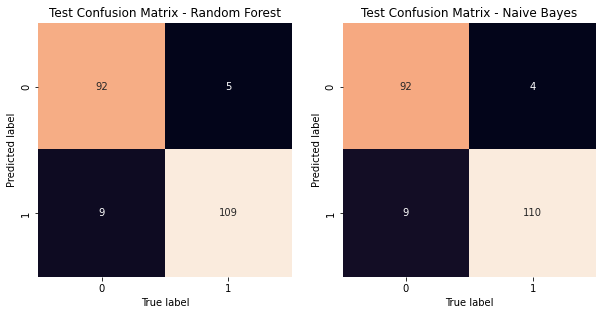

In [ ]:
testing_classic_ML(X_train, y_train,X_test,y_test)

We see that both achieved similar results, **accuracy of about 94% and F1 score of 0.94**. 

Our model's **accuracy is 98.6% and F1=0.987**. Clearly it achieved better results.

# Conclusions

In this project we created a breast cancer classifier. 

Our first challange was balancing the data, the fact it is not large lead us to choose augmentation by implementing a VAE model.

Augmenting using the VAE was successful and also lead to some intresting results- a relatively low value of beta in the loss function yielded better results, it made the new created samples more natural.

Then we created the classifier and tested different architectures. We found out that for a data of this size a relatively small number of epochs is sufficient, along with hyperparameters optimizations.

Finally we compared our model to State-Of-The-Art methods and outperformed them. 

We achieved a very high accuracy and F1 scores and are very pleased with the results. We enjoyed working on this project and overcoming the challenges it presented.

# References

[1] https://www.kaggle.com/datasets/yasserh/breast-cancer-dataset

[2] https://towardsdatascience.com/review-of-gans-for-tabular-data-a30a2199342

[3] https://github.com/Diyago/GAN-for-tabular-data